In [1]:
import json
from pathlib import Path

# Find all saved raw JSON files
raw_folder = Path("../data/raw")
json_files = sorted(raw_folder.glob("*/*.json"))

print(f"Number of JSON files found: {len(json_files)}")

# Check that raw weather files exist
if not json_files:
    raise FileNotFoundError("No raw weather JSON files found.")

# Select a sample file and identify its city
sample_file = json_files[0]
sample_city = sample_file.stem.split("_")[0].title()

print(f"Sample file: {sample_file.name}")
print(f"Sample city: {sample_city}")

# Open the sample file
with sample_file.open("r", encoding="utf-8") as file:
    payload = json.load(file)

# Inspect the main sections
print(payload.keys())


Number of JSON files found: 104
Sample file: birmingham_20261117T211330.json
Sample city: Birmingham
dict_keys(['latitude', 'longitude', 'generationtime_ms', 'utc_offset_seconds', 'timezone', 'timezone_abbreviation', 'elevation', 'hourly_units', 'hourly'])


In [2]:
# Inspect the hourly weather data
payload["hourly"].keys()

dict_keys(['time', 'temperature_2m', 'relative_humidity_2m', 'apparent_temperature', 'precipitation', 'wind_speed_10m', 'weather_code'])

In [3]:
# Inspect the units
payload["hourly_units"]

{'time': 'iso8601',
 'temperature_2m': '°C',
 'relative_humidity_2m': '%',
 'apparent_temperature': '°C',
 'precipitation': 'mm',
 'wind_speed_10m': 'km/h',
 'weather_code': 'wmo code'}

In [4]:
import pandas as pd

df_sample = pd.DataFrame(payload["hourly"])

df_sample["city"] = sample_city
df_sample["latitude"] = payload["latitude"]
df_sample["longitude"] = payload["longitude"]

df_sample.head()


,time,temperature_2m,relative_humidity_2m,apparent_temperature,precipitation,wind_speed_10m,weather_code,city,latitude,longitude
0,2026-11-16T00:00,5.4,88,1.4,0.0,17.3,2,Birmingham,52.488224,-1.909378
1,2026-11-16T01:00,4.7,87,1.0,0.0,14.0,1,Birmingham,52.488224,-1.909378
2,2026-11-16T02:00,4.3,86,0.7,0.0,13.0,1,Birmingham,52.488224,-1.909378
3,2026-11-16T03:00,3.8,82,-0.1,0.0,13.3,0,Birmingham,52.488224,-1.909378
4,2026-11-16T04:00,3.2,82,-0.8,0.0,13.3,2,Birmingham,52.488224,-1.909378


In [5]:
def flatten(payload: dict, city_name: str) -> pd.DataFrame:
    """
    Convert one city's hourly weather JSON into a DataFrame.
    """

    df = pd.DataFrame(payload["hourly"])

    df["city"] = city_name
    df["latitude"] = payload["latitude"]
    df["longitude"] = payload["longitude"]

    return df

In [6]:
df_sample = flatten(payload, sample_city)

df_sample.head()

,time,temperature_2m,relative_humidity_2m,apparent_temperature,precipitation,wind_speed_10m,weather_code,city,latitude,longitude
0,2026-11-16T00:00,5.4,88,1.4,0.0,17.3,2,Birmingham,52.488224,-1.909378
1,2026-11-16T01:00,4.7,87,1.0,0.0,14.0,1,Birmingham,52.488224,-1.909378
2,2026-11-16T02:00,4.3,86,0.7,0.0,13.0,1,Birmingham,52.488224,-1.909378
3,2026-11-16T03:00,3.8,82,-0.1,0.0,13.3,0,Birmingham,52.488224,-1.909378
4,2026-11-16T04:00,3.2,82,-0.8,0.0,13.3,2,Birmingham,52.488224,-1.909378


In [7]:
# Find all JSON files in the raw data folders
json_files = list(raw_folder.glob("*/*.json"))

# Keep the latest file for each city
latest_files = {}

for file_path in json_files:
    city_name = file_path.name.split("_")[0]

    if (
        city_name not in latest_files
        or file_path.stat().st_mtime
        > latest_files[city_name].stat().st_mtime
    ):
        latest_files[city_name] = file_path

print("Latest files selected:")

for city, file_path in latest_files.items():
    print(city, ":", file_path)

Latest files selected:
birmingham : ..\data\raw\2026-11-25\birmingham_20261125T011212.json
cardiff : ..\data\raw\2026-11-25\cardiff_20261125T011213.json
edinburgh : ..\data\raw\2026-11-25\edinburgh_20261125T011213.json
london : ..\data\raw\2026-11-25\london_20261125T011213.json
manchester : ..\data\raw\2026-11-25\manchester_20261125T011214.json


In [8]:
# Load and flatten the latest file for each city
city_dfs = []

for city_name, file_path in latest_files.items():

    with file_path.open("r", encoding="utf-8") as file:
        payload = json.load(file)

    city_df = flatten(payload, city_name.title())

    city_dfs.append(city_df)

# Combine all cities into one DataFrame
df = pd.concat(city_dfs, ignore_index=True)

print("Combined DataFrame created!")

Combined DataFrame created!


In [9]:
df.head()

,time,temperature_2m,relative_humidity_2m,apparent_temperature,precipitation,wind_speed_10m,weather_code,city,latitude,longitude
0,2026-11-24T00:00,3.4,82,-0.5,0.5,13.0,53,Birmingham,52.488224,-1.909378
1,2026-11-24T01:00,3.1,90,-0.5,0.9,12.2,53,Birmingham,52.488224,-1.909378
2,2026-11-24T02:00,3.0,93,-0.7,0.9,13.0,53,Birmingham,52.488224,-1.909378
3,2026-11-24T03:00,3.0,93,-0.8,0.1,13.7,51,Birmingham,52.488224,-1.909378
4,2026-11-24T04:00,3.1,92,-0.7,0.0,13.7,3,Birmingham,52.488224,-1.909378


In [10]:
df["city"].unique()

<ArrowStringArray>
['Birmingham', 'Cardiff', 'Edinburgh', 'London', 'Manchester']
Length: 5, dtype: str

In [11]:
df["city"].value_counts()

city
Birmingham    48
Cardiff       48
Edinburgh     48
London        48
Manchester    48
Name: count, dtype: int64

In [12]:
df.shape

(240, 10)

In [13]:
df.dtypes

time                        str
temperature_2m          float64
relative_humidity_2m      int64
apparent_temperature    float64
precipitation           float64
wind_speed_10m          float64
weather_code              int64
city                        str
latitude                float64
longitude               float64
dtype: object

In [14]:
# Convert timestamps to datetime
df["time"] = pd.to_datetime(df["time"])

# Verify the converted data type
print("Time column data type:", df["time"].dtype)

df.head()

Time column data type: datetime64[us]


,time,temperature_2m,relative_humidity_2m,apparent_temperature,precipitation,wind_speed_10m,weather_code,city,latitude,longitude
0,2026-11-24 00:00:00,3.4,82,-0.5,0.5,13.0,53,Birmingham,52.488224,-1.909378
1,2026-11-24 01:00:00,3.1,90,-0.5,0.9,12.2,53,Birmingham,52.488224,-1.909378
2,2026-11-24 02:00:00,3.0,93,-0.7,0.9,13.0,53,Birmingham,52.488224,-1.909378
3,2026-11-24 03:00:00,3.0,93,-0.8,0.1,13.7,51,Birmingham,52.488224,-1.909378
4,2026-11-24 04:00:00,3.1,92,-0.7,0.0,13.7,3,Birmingham,52.488224,-1.909378


In [15]:
df.isna().sum()

time                    0
temperature_2m          0
relative_humidity_2m    0
apparent_temperature    0
precipitation           0
wind_speed_10m          0
weather_code            0
city                    0
latitude                0
longitude               0
dtype: int64

In [16]:
df.describe()

,time,temperature_2m,relative_humidity_2m,apparent_temperature,precipitation,wind_speed_10m,weather_code,latitude,longitude
count,240,240.000000,240.000000,240.000000,240.000000,240.000000,240.000000,240.000000,240.000000
mean,2026-11-24 23:30:00,5.126250,79.808333,1.588750,0.062917,11.992083,8.716667,52.983542,-2.133569
min,2026-11-24 00:00:00,1.100000,61.000000,-2.300000,0.000000,1.400000,0.000000,51.480080,-3.206848
25%,2026-11-24 11:45:00,3.800000,75.000000,0.300000,0.000000,9.700000,3.000000,51.511470,-3.192810
50%,2026-11-24 23:30:00,4.900000,81.000000,1.300000,0.000000,12.200000,3.000000,52.488224,-2.228027
75%,2026-11-25 11:15:00,6.000000,86.000000,2.500000,0.000000,14.800000,3.000000,53.478767,-1.909378
max,2026-11-25 23:00:00,10.700000,93.000000,7.800000,2.600000,19.400000,63.000000,55.959167,-0.130783
std,NaN,1.852472,7.618845,1.957199,0.264970,3.782306,16.405267,1.663127,1.128787


In [17]:
df.duplicated(subset=["city", "time"]).sum()

np.int64(0)

In [18]:
df[df.duplicated(subset=["city", "time"], keep=False)].sort_values(
    ["city", "time"]
)

,time,temperature_2m,relative_humidity_2m,apparent_temperature,precipitation,wind_speed_10m,weather_code,city,latitude,longitude


In [19]:
sorted(df["weather_code"].dropna().unique())

[np.int64(0),
 np.int64(1),
 np.int64(2),
 np.int64(3),
 np.int64(51),
 np.int64(53),
 np.int64(55),
 np.int64(61),
 np.int64(63)]

In [20]:
df["time"] = pd.to_datetime(df["time"])

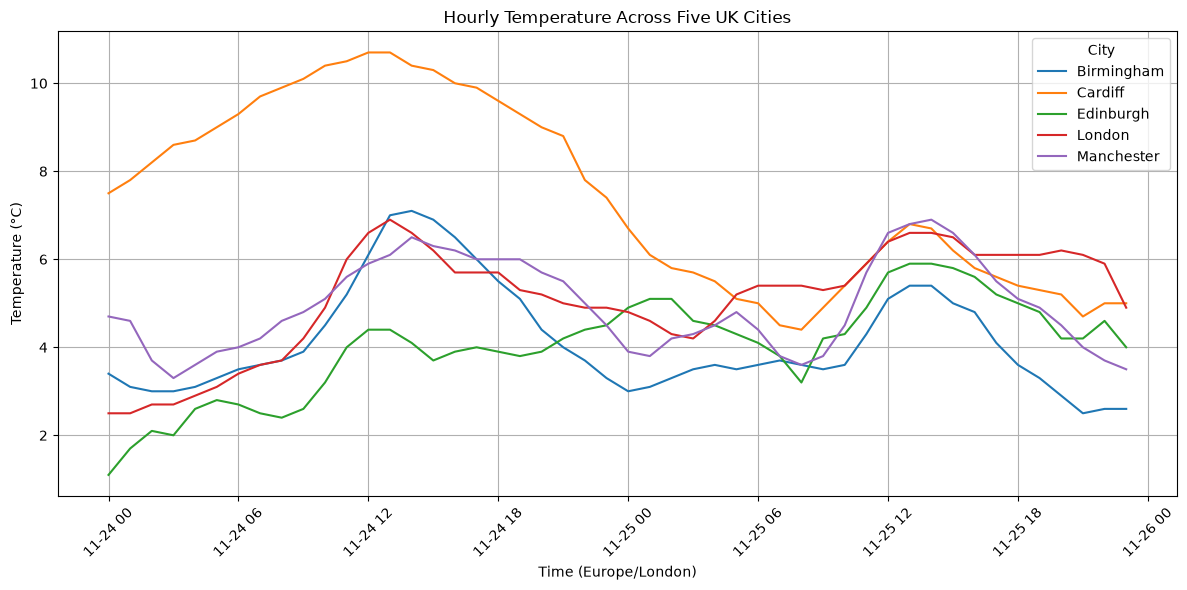

In [21]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))

for city in df["city"].unique():
    city_data = df[df["city"] == city].sort_values("time")

    plt.plot(
        city_data["time"],
        city_data["temperature_2m"],
        label=city
    )

plt.title("Hourly Temperature Across Five UK Cities")
plt.xlabel("Time (Europe/London)")
plt.ylabel("Temperature (°C)")
plt.legend(title="City")
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()

In [22]:
df.duplicated(subset=["city", "time"]).sum()

np.int64(0)

In [23]:
df.shape

(240, 10)

## Five Findings

**Dataset:** Latest raw weather files extracted on 25 November 2026, covering 24–25 November 2026. These findings describe the dataset used during this notebook execution. Results may change when newer weather files are selected.

1. **Data volume:** The combined DataFrame contains **240 rows and 10 columns**, covering five UK cities: Birmingham, Cardiff, Edinburgh, London and Manchester. Each city has 48 hourly weather records.

2. **Data types:** The `time` column was initially loaded as text (`str`). I converted all **240 timestamp values** to datetime using `pd.to_datetime()` so that records can be sorted chronologically and used correctly for time-series analysis and plotting. The remaining nine columns have appropriate numerical or string data types.

3. **Missing values:** The profiling found **0 missing values across all 10 columns**. All 240 records contain complete values for timestamps, weather measurements, city names and geographical coordinates.

4. **Duplicate records:** There are **0 duplicate records** based on the combination of `city` and `time`. This confirms that each city has only one record for each hourly timestamp in the combined DataFrame.

5. **Weather values:** The temperature range is **1.1°C to 10.7°C**, with an average temperature of approximately **5.13°C** across all five cities. The nine distinct weather codes are **0, 1, 2, 3, 51, 53, 55, 61 and 63**. These represent clear sky, mainly clear, partly cloudy, overcast, different intensities of drizzle and slight to moderate rain, according to WMO weather interpretation codes.